# Customer Churn - EDA
Steps: import, load data, basic stats, visualisation

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set(color_codes=True)

## 2. Load data

In [2]:
client_df = pd.read_csv("../data/client_data.csv")
price_df = pd.read_csv("../data/price_data.csv")

In [3]:
client_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


In [4]:
price_df.head(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0


Client data has numeric + categorical columns. Price data is numeric with many zeros.

## 3. Basic statistics

In [5]:
print(client_df.shape, price_df.shape)
client_df.info()

(14606, 26) (193002, 8)
<class 'pandas.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  str    
 1   channel_sales                   14606 non-null  str    
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  str    
 6   date_end                        14606 non-null  str    
 7   date_modif_prod                 14606 non-null  str    
 8   date_renewal                    14606 non-null  str    
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent

In [6]:
price_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  str    
 1   price_date          193002 non-null  str    
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), str(2)
memory usage: 11.8 MB


Date columns are strings, will convert them later.

In [7]:
# missing values and duplicates
print(client_df.isnull().sum().sum(), price_df.isnull().sum().sum())
print(client_df.duplicated().sum(), price_df.duplicated().sum())

0 0
0 0


In [8]:
client_df.describe()

,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,1868.614880,1399.762906,0.966726,63.086871,0.137283,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
std,5.734653e+05,1.629731e+05,64364.196422,2387.571531,3247.786255,5.108289,66.165783,0.024623,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,494.995000,0.000000,0.000000,16.180000,0.116340,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,1112.875000,314.000000,0.000000,18.795000,0.143166,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2401.790000,1745.750000,0.000000,131.030000,0.146348,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,82902.830000,175375.000000,30.000000,599.310000,0.273963,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000


Data is highly skewed (see percentiles vs max).

In [9]:
price_df.describe()

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
std,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221


## 4. Visualisation

In [10]:
# helper: stacked bar of retention vs churn (%)
def plot_stacked_bars(df, title, size=(10, 6), rot=0, legend="upper right"):
    ax = df.plot(kind="bar", stacked=True, figsize=size, rot=rot, title=title)
    for p in ax.patches:
        h = round(p.get_height(), 1)
        if h == 0:
            continue
        ax.annotate(h, (p.get_x() + p.get_width() / 2, p.get_y() + p.get_height() / 2),
                    ha="center", color="white", size=12)
    plt.legend(["Retention", "Churn"], loc=legend)
    plt.ylabel("Company base (%)")
    plt.show()

# helper: churn % within each category of a column
def churn_pct(col):
    t = pd.crosstab(client_df[col], client_df["churn"])
    return t.div(t.sum(axis=1), axis=0) * 100

# helper: histogram split by churn
def plot_distribution(df, col, ax, bins=50):
    temp = pd.DataFrame({"Retention": df[df["churn"] == 0][col],
                         "Churn": df[df["churn"] == 1][col]})
    temp.plot(kind="hist", bins=bins, ax=ax, stacked=True)
    ax.set_xlabel(col)
    ax.ticklabel_format(style="plain", axis="x")

### Churn

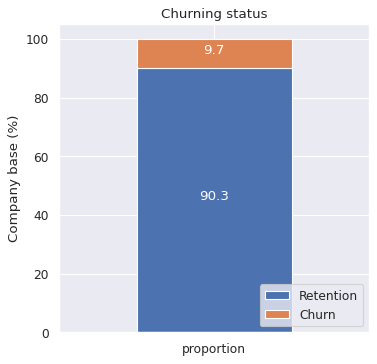

In [11]:
churn_total = client_df["churn"].value_counts(normalize=True) * 100
plot_stacked_bars(churn_total.sort_index().to_frame().T, "Churning status", (5, 5), legend="lower right")

About 10% of customers churned.

### Sales channel

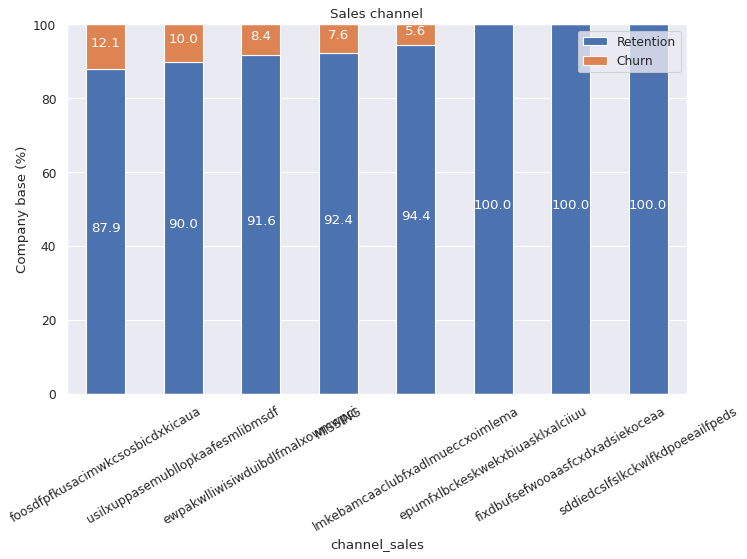

In [12]:
plot_stacked_bars(churn_pct('channel_sales').sort_values(by=1, ascending=False), 'Sales channel', rot=30)

Churn varies by channel, so it may be a useful feature.

### Consumption

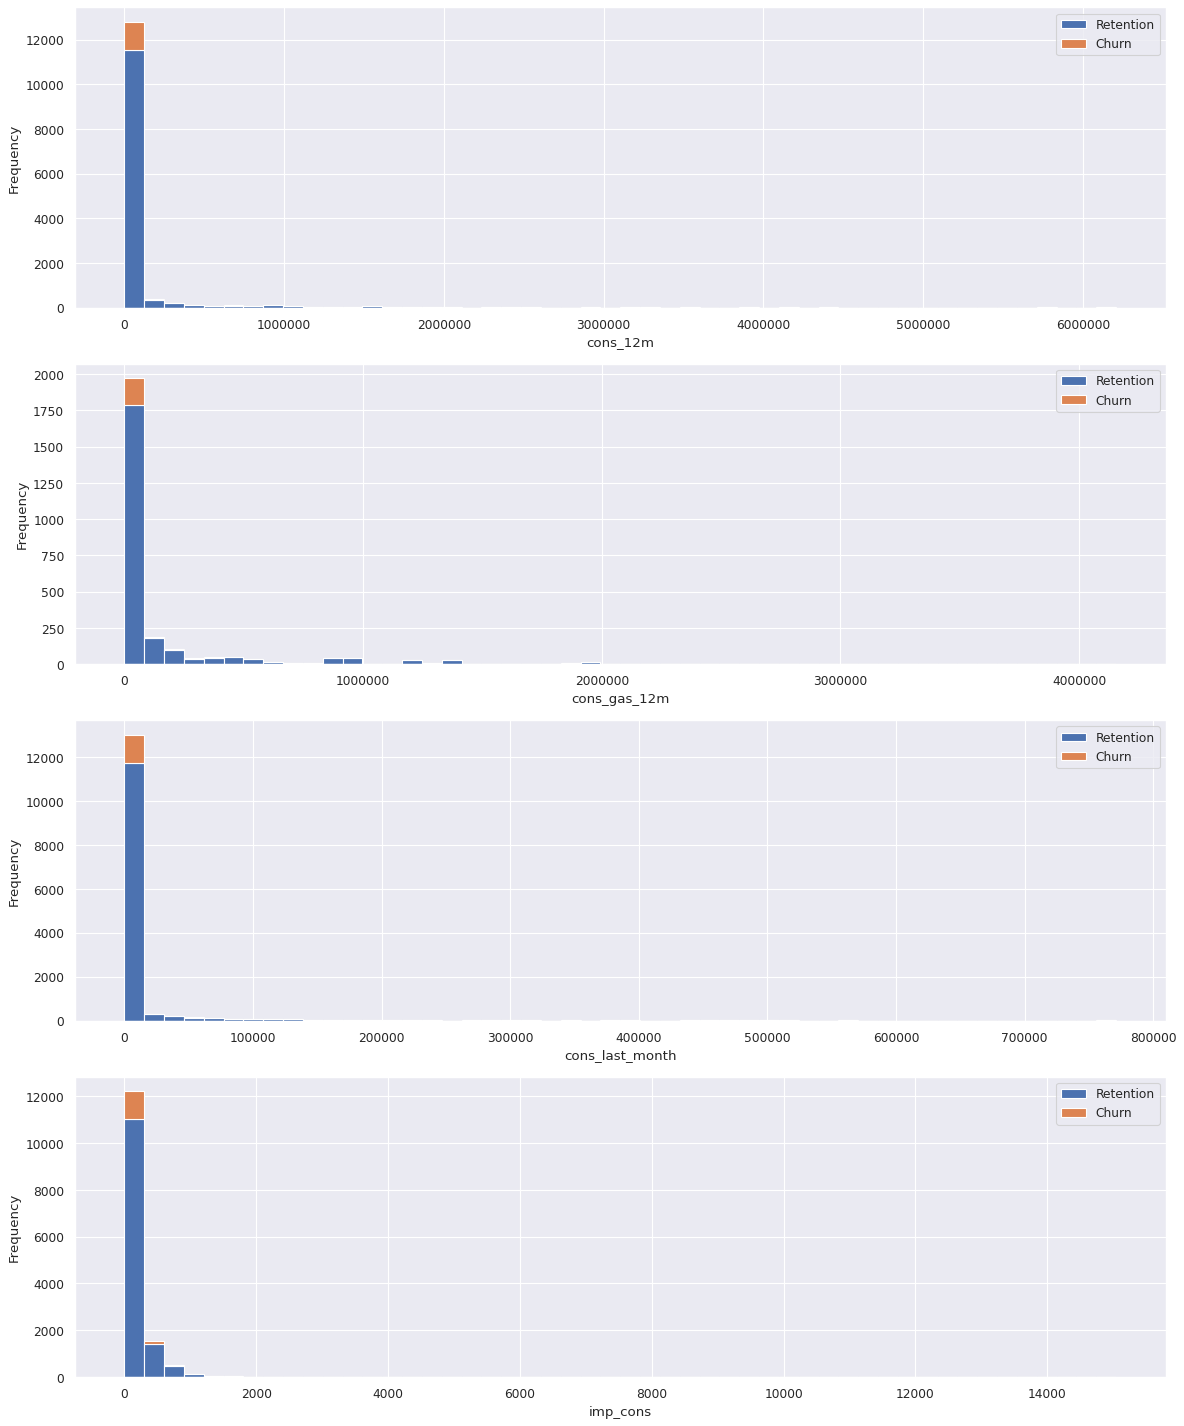

In [13]:
fig, axs = plt.subplots(nrows=4, figsize=(15, 18))
plot_distribution(client_df, "cons_12m", axs[0])
plot_distribution(client_df[client_df["has_gas"] == "t"], "cons_gas_12m", axs[1])
plot_distribution(client_df, "cons_last_month", axs[2])
plot_distribution(client_df, "imp_cons", axs[3])
plt.tight_layout()

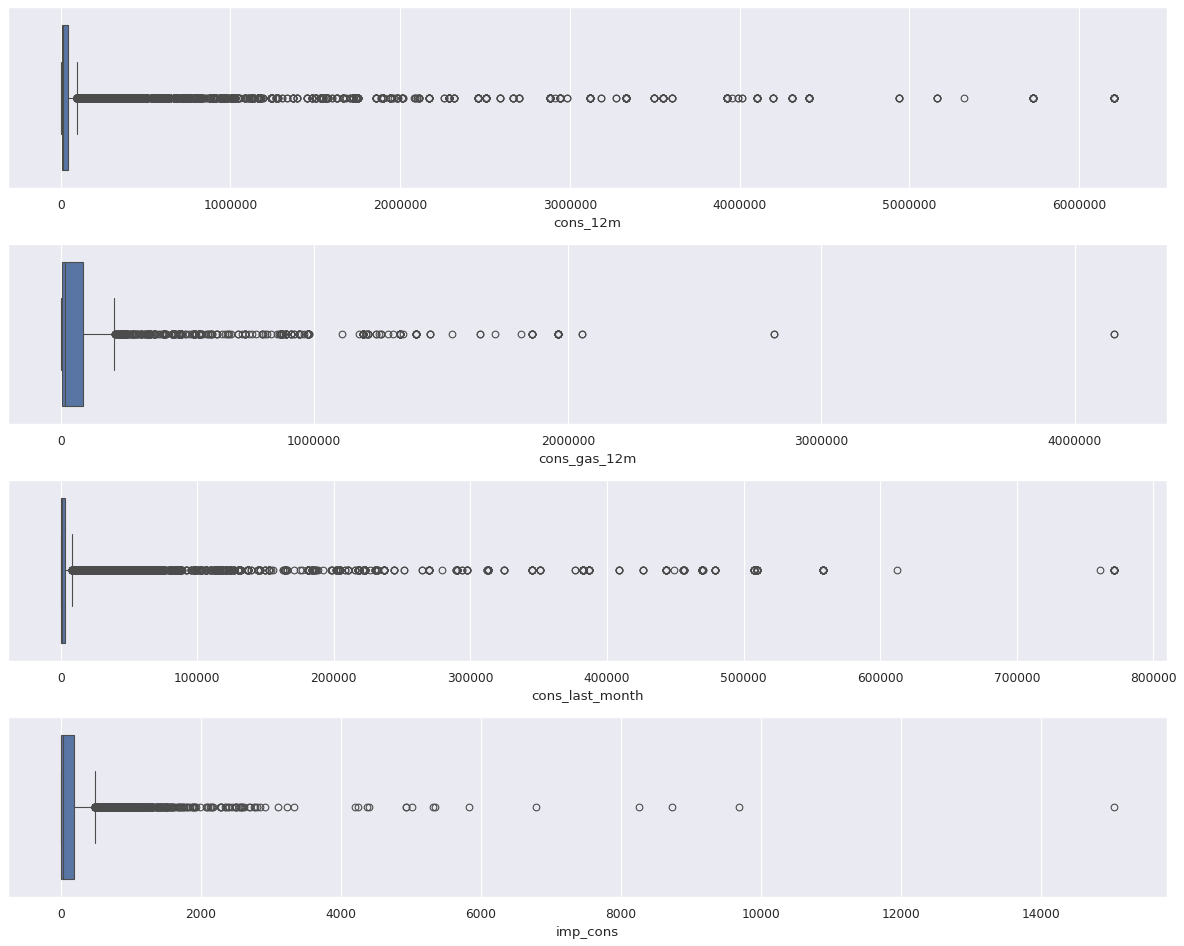

In [14]:
# boxplots to spot outliers
fig, axs = plt.subplots(nrows=4, figsize=(15, 12))
sns.boxplot(x=client_df["cons_12m"], ax=axs[0])
sns.boxplot(x=client_df[client_df["has_gas"] == "t"]["cons_gas_12m"], ax=axs[1])
sns.boxplot(x=client_df["cons_last_month"], ax=axs[2])
sns.boxplot(x=client_df["imp_cons"], ax=axs[3])
for ax in axs:
    ax.ticklabel_format(style="plain", axis="x")
plt.tight_layout()

Consumption is right-skewed with many outliers. Will handle in feature engineering.

### Forecast

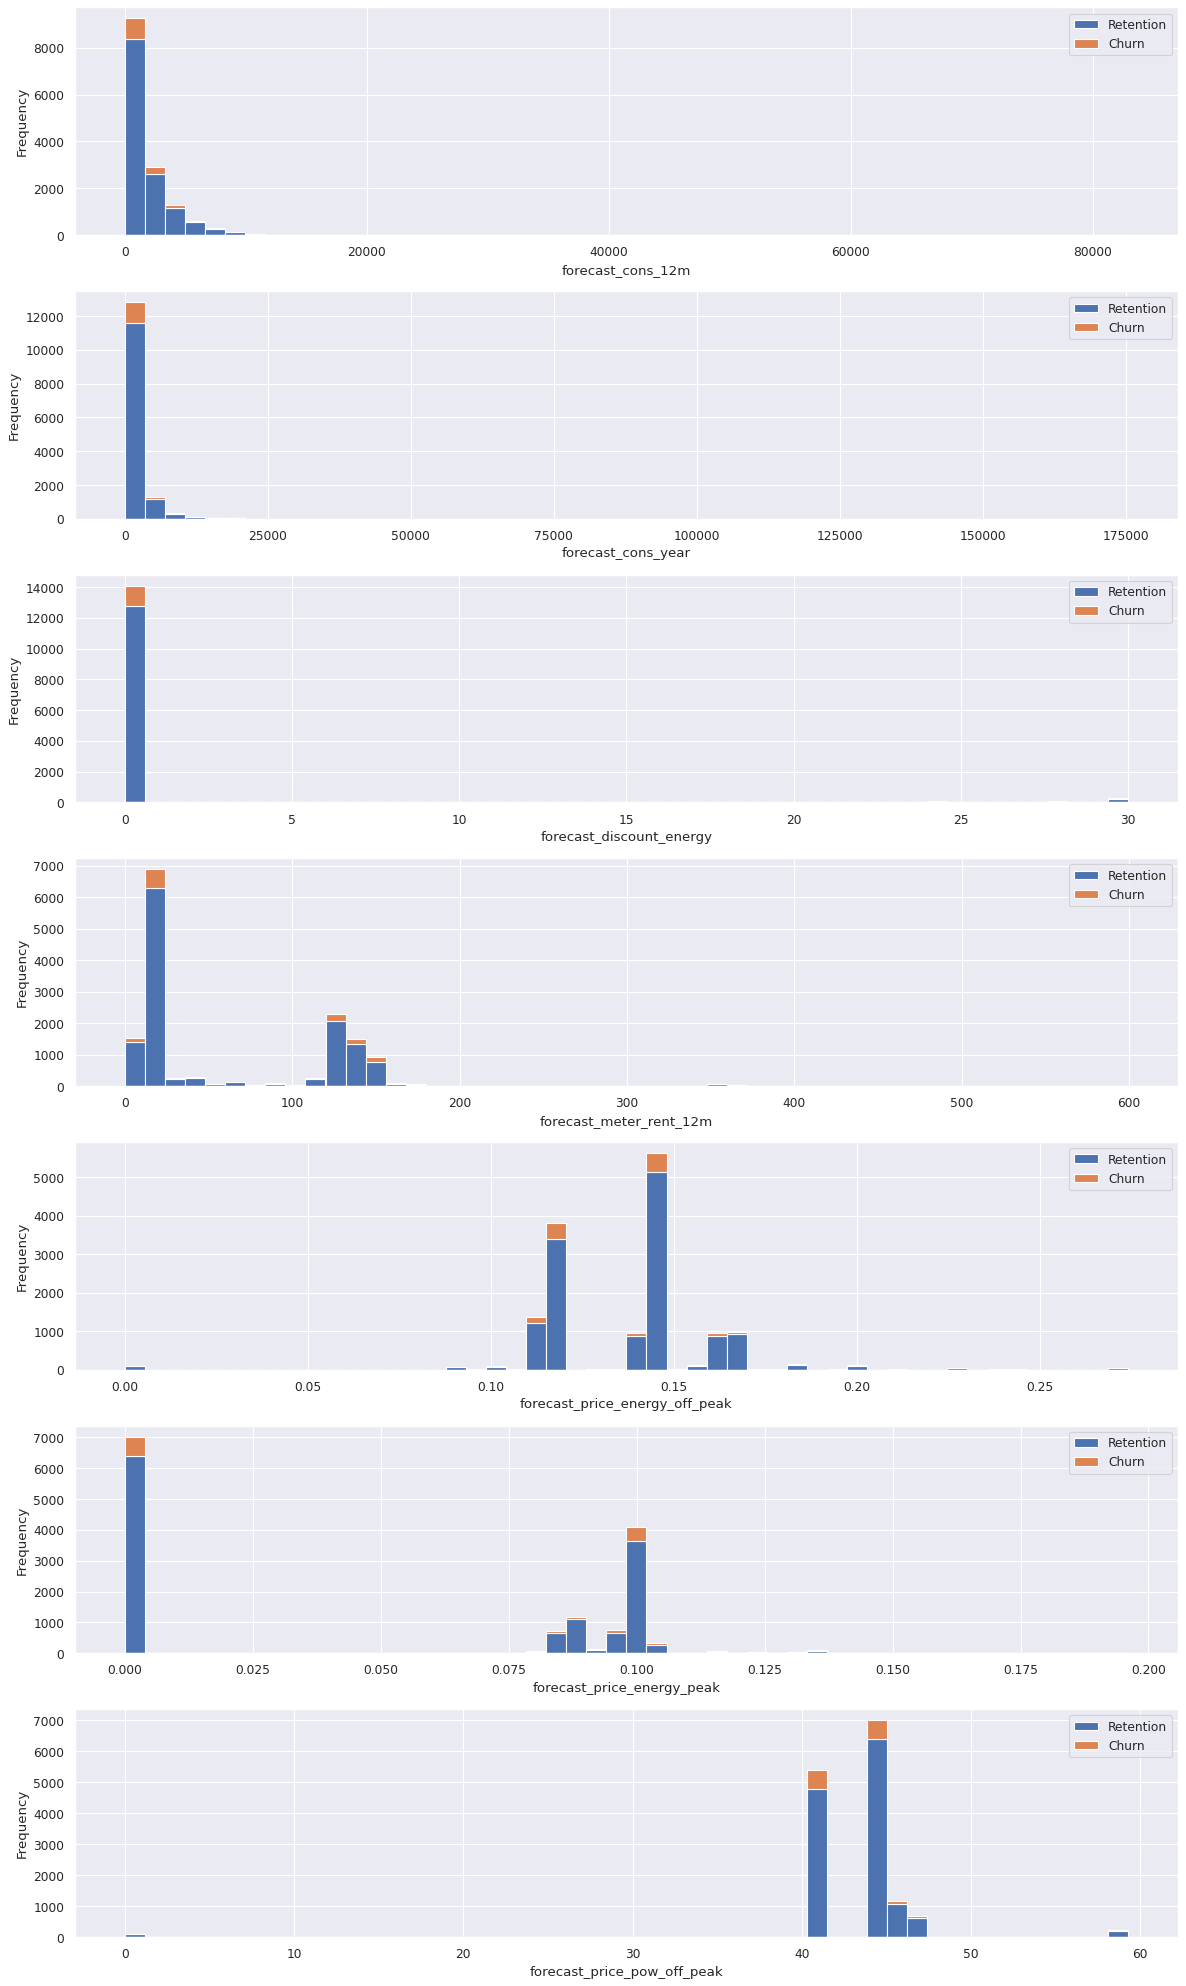

In [15]:
forecast_cols = ["forecast_cons_12m", "forecast_cons_year", "forecast_discount_energy",
                 "forecast_meter_rent_12m", "forecast_price_energy_off_peak",
                 "forecast_price_energy_peak", "forecast_price_pow_off_peak"]

fig, axs = plt.subplots(nrows=len(forecast_cols), figsize=(15, 25))
for col, ax in zip(forecast_cols, axs):
    plot_distribution(client_df, col, ax)
plt.tight_layout()

Same skewness here, will transform later.

### Contract type (has gas)

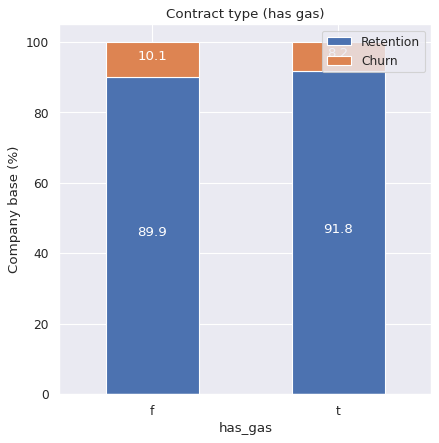

In [16]:
plot_stacked_bars(churn_pct('has_gas'), 'Contract type (has gas)', (6, 6))

### Margins

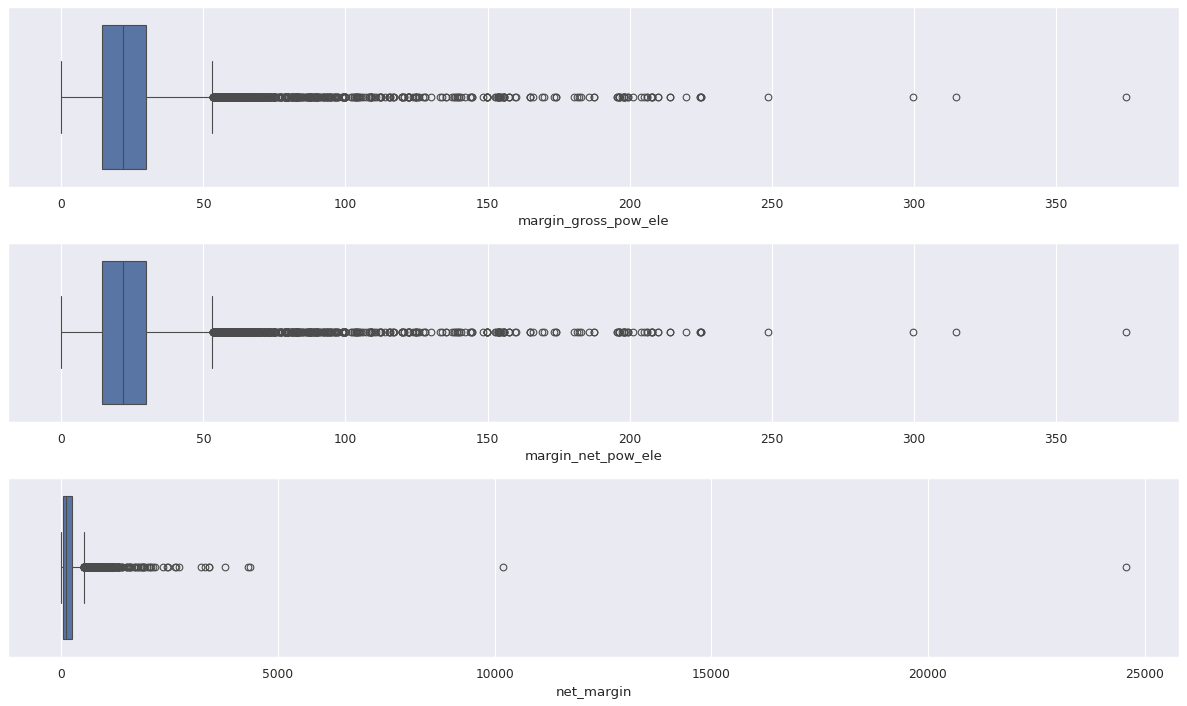

In [17]:
fig, axs = plt.subplots(nrows=3, figsize=(15, 9))
for col, ax in zip(["margin_gross_pow_ele", "margin_net_pow_ele", "net_margin"], axs):
    sns.boxplot(x=client_df[col], ax=ax)
plt.tight_layout()

Some outliers in margins too.

### Subscribed power

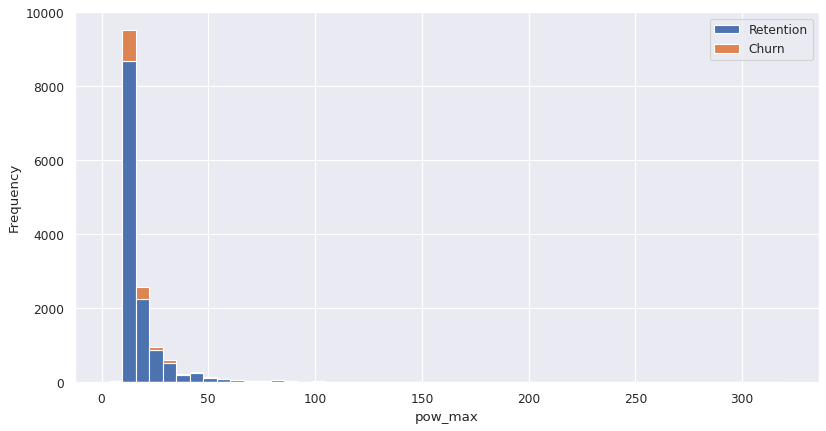

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_distribution(client_df, "pow_max", ax)

### Other columns

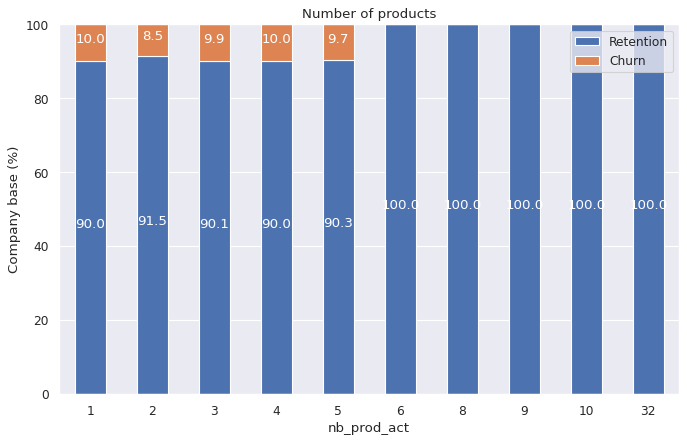

In [19]:
plot_stacked_bars(churn_pct('nb_prod_act'), 'Number of products')

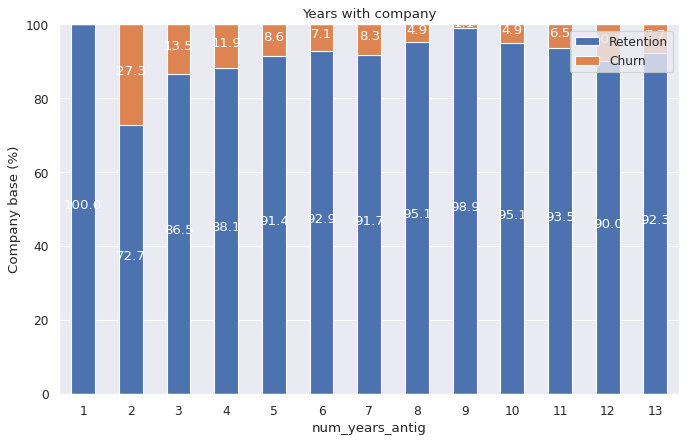

In [20]:
plot_stacked_bars(churn_pct('num_years_antig'), 'Years with company')

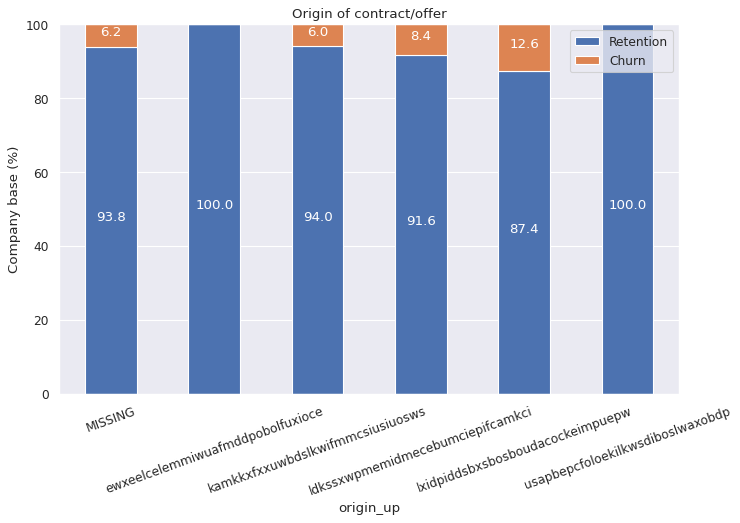

In [21]:
plot_stacked_bars(churn_pct('origin_up'), 'Origin of contract/offer', rot=20)

### Price data

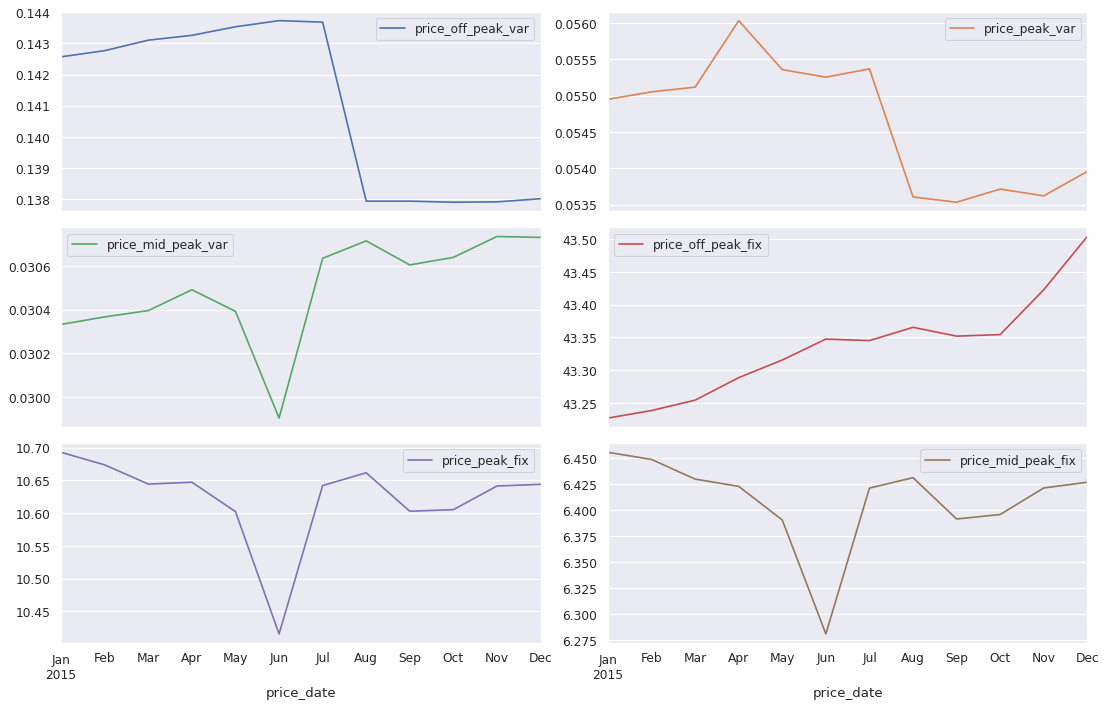

In [22]:
price_df["price_date"] = pd.to_datetime(price_df["price_date"])

# average price per month
price_cols = ["price_off_peak_var", "price_peak_var", "price_mid_peak_var",
              "price_off_peak_fix", "price_peak_fix", "price_mid_peak_fix"]
price_df.groupby("price_date")[price_cols].mean().plot(subplots=True, layout=(3, 2), figsize=(14, 9))
plt.tight_layout()

## Summary
- ~10% churn
- Many numeric columns are skewed with outliers
- Date columns need converting
- Sales channel, products, tenure and origin show churn differences

Next: feature engineering.